# 5. lecke – King County lakásárbecslés

**Feltevés.** Az eladás napján ismert jellemzők használhatók, a comps csak korábbi tanítóeladásokból származhat, és az ingatlanazonosító a megadott mezőkből képzett közelítés. A validáció és a teszt jövőbeli időblokkok; ugyanaz a közelítő ingatlan nem szerepelhet a tanító- és az értékelt részben.

## 1. Kérdés és előre rögzített mérőszámok

Az előrejelzett mennyiség az eladási ár USD-ben; fedezetértékelésnél a túlbecslés lehet költségesebb, ezért a nagy dollárhibákat büntető RMSE-t is figyelem. Fő, arányos mutató a WAPE; mellette előre rögzítem az RMSE-t, MAE-t, RMSLE-t, R²-t és a jósolt/tényleges összeg arányát, utóbbi a log-cél visszaalakítási torzítását jelzi. A végső modellválasztás kizárólag fejlesztési foldokon történik, a tesztet a végén egyszer értékelem.


In [1]:
from pathlib import Path
import sys

module_dir = Path("lesson 5")
if not module_dir.is_dir():
    module_dir = Path(".")
sys.path.insert(0, str(module_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import house as H
from results import compute

plt.rcParams["figure.dpi"] = 80
R, O = compute()


## 1b. Feltárás, tisztítás és időrendi felosztás

A célár ferde eloszlását nyers és log1p skálán, a földrajzi árkülönbséget, a havi mediánt és a lakóterület kapcsolatát a fejlesztési adaton ábrázolom. A ≥10 hálószobás öt sort – köztük a 33 hálószobásat – elhagyom, mert valószínű adathibák; az árakat nem csonkolom, a `yr_renovated=0` értéket „nem volt felújításként” jelzem, a ZIP-kód pedig kategória.

A teszt az időrend utolsó 20%-a, 2015-03-10-től: a véletlen vágás szomszédos eladásokat keverne a tanítóba. A 13 hónap miatt a teszt egyetlen szezon, a fák nem extrapolálnak; a három kiterjedő időablakos foldban minden validációs ingatlan korábbi tanítóeladását kizárom.


sorok: 21,608/21,613 | fejlesztés: 17,277 | záró teszt (egyszer, a végén): 4,331 | vágás: 2015-03-10 | modell: XGBoost
Az eredeti maximum 33 hálószoba; a felújítási év 0 az esetek 95.8%-ában szerepel.
Árátlag $540,088, medián $450,000, maximum $7,700,000; hiányzó érték 0.
5 sort hagytam el a legalább 10 hálószobás szélsőség miatt; 392 sor osztozik 195 ismétlődő kulcson. A fejlesztési utolsó dátum 2015-03-09, és 99 korábbi eladást zártam ki a teszt miatt.


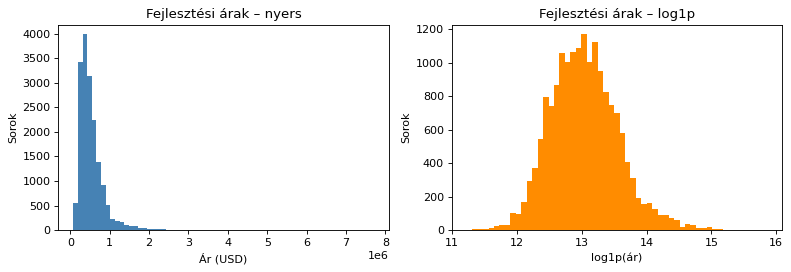

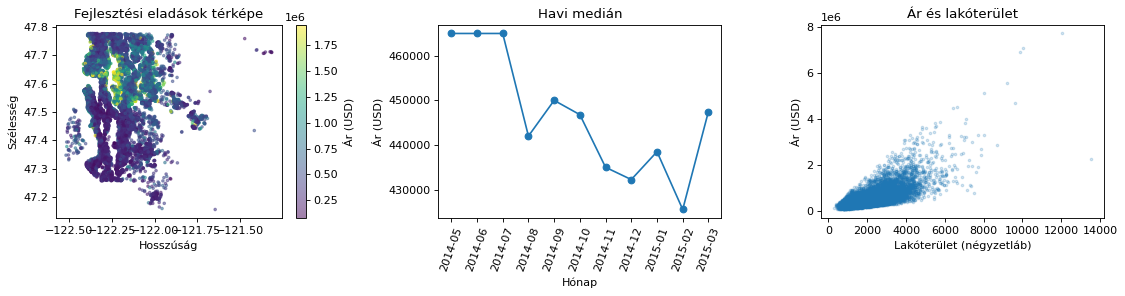

A log1p skála tömöríti a hosszú jobb farkat; az 1M USD feletti arány 6.8%, és 70 ZIP-kód szerepel.


In [2]:
d = O["frame"]
dev = d.loc[d["date"] < H.DEV_END]
print(
    f"sorok: {R['data']['rows']:,}/{R['data']['source_rows']:,} | "
    f"fejlesztés: {R['data']['dev_rows']:,} | "
    f"záró teszt (egyszer, a végén): {R['data']['test_rows']:,} | "
    f"vágás: {R['data']['dev_end']} | modell: {R['data']['engine']}"
)
print(
    f"Az eredeti maximum {R['data']['original_max_bedrooms']} hálószoba; a felújítási év 0 "
    f"az esetek {R['data']['renovation_zero_rate']:.1%}-ában szerepel."
)
print(
    f"Árátlag ${R['data']['mean_price']:,.0f}, medián ${R['data']['median_price']:,.0f}, "
    f"maximum ${R['data']['max_price']:,.0f}; hiányzó érték {R['data']['missing_values']}."
)
print(
    f"{R['data']['removed_bedroom_rows']} sort hagytam el a legalább 10 hálószobás szélsőség miatt; "
    f"{R['data']['repeat_rows']} sor osztozik {R['data']['repeat_properties']} ismétlődő kulcson. "
    f"A fejlesztési utolsó dátum {dev.date.max():%Y-%m-%d}, és {R['data']['test_purged_rows']} korábbi eladást zártam ki a teszt miatt."
)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(dev["price"], bins=65, color="steelblue")
ax[0].set(title="Fejlesztési árak – nyers", xlabel="Ár (USD)", ylabel="Sorok")
ax[1].hist(np.log1p(dev["price"]), bins=55, color="darkorange")
ax[1].set(title="Fejlesztési árak – log1p", xlabel="log1p(ár)", ylabel="Sorok")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
s = ax[0].scatter(dev["long"], dev["lat"], c=dev["price"], s=5, alpha=.5, cmap="viridis",
                  vmax=dev["price"].quantile(.99))
ax[0].set(title="Fejlesztési eladások térképe", xlabel="Hosszúság", ylabel="Szélesség")
fig.colorbar(s, ax=ax[0], label="Ár (USD)")
monthly = dev.assign(month=dev["date"].dt.to_period("M")).groupby("month")["price"].median()
ax[1].plot(monthly.index.astype(str), monthly.values, marker="o")
ax[1].tick_params(axis="x", rotation=70)
ax[1].set(title="Havi medián", xlabel="Hónap", ylabel="Ár (USD)")
ax[2].scatter(dev["sqft_living"], dev["price"], s=5, alpha=.2)
ax[2].set(title="Ár és lakóterület", xlabel="Lakóterület (négyzetláb)", ylabel="Ár (USD)")
plt.tight_layout()
plt.show()
print(
    f"A log1p skála tömöríti a hosszú jobb farkat; az 1M USD feletti arány "
    f"{R['data']['over_million_rate']:.1%}, és {R['data']['zip_count']} ZIP-kód szerepel."
)


## 2. Modell-létra – azonos időrendi foldok

A lineáris `lr_fair` ZIP one-hot kódolást, standardizált numerikus jellemzőket és log-területet használ. Az `lr_naive` a ZIP-et szándékosan egyetlen számként kezeli: negatív példa a kategóriák rendezett számként való bevezetésére; a faalapú modellek log1p áron tanulnak.


In [3]:
ladder = R["ladder"].copy()
ladder["fold_rmse"] = ladder["fold_rmse"].map(lambda values: [round(value) for value in values])
display(ladder[["modell", "rmse", "mae", "wape", "rmsle", "r2", "ratio", "fold_rmse"]].style.format({
    "rmse": "${:,.0f}", "mae": "${:,.0f}", "wape": "{:.3f}", "rmsle": "{:.3f}",
    "r2": "{:.3f}", "ratio": "{:.3f}",
}))
best = ladder.iloc[0]
print(
    f"A legkisebb OOF-RMSE a(z) {best['modell']} modellé (${best['rmse']:,.0f}); "
    f"WAPE={best['wape']:.3f}, R²={best['r2']:.3f}, összegarány={best['ratio']:.3f}."
)
print(
    f"A fold-RMSE-k {best['fold_rmse']}; az átlag baseline RMSE-je "
    f"${ladder.loc[ladder.modell == 'átlag', 'rmse'].iloc[0]:,.0f}. "
    f"Az XGBoost helyett használt eljárás: {R['data']['engine']}."
)


,modell,rmse,mae,wape,rmsle,r2,ratio,fold_rmse
0,lr_fair,"$128,240","$72,745",0.138,0.184,0.877,0.970,"[124812, 128423, 131464]"
1,xgb,"$132,921","$69,342",0.132,0.178,0.868,0.968,"[144019, 127727, 125361]"
2,forest,"$139,752","$71,402",0.136,0.182,0.854,0.964,"[136897, 141787, 140856]"
3,tree,"$174,057","$88,768",0.169,0.220,0.774,0.974,"[176033, 177452, 169047]"
4,lr_naive,"$186,576","$106,505",0.202,0.253,0.740,0.962,"[178455, 168425, 208115]"
5,ZIP-medián,"$294,077","$154,300",0.293,0.371,0.354,0.902,"[299629, 304143, 279292]"
6,átlag,"$366,217","$237,084",0.451,0.564,-0.002,1.030,"[376772, 366368, 355088]"


A legkisebb OOF-RMSE a(z) lr_fair modellé ($128,240); WAPE=0.138, R²=0.877, összegarány=0.970.
A fold-RMSE-k [124812, 128423, 131464]; az átlag baseline RMSE-je $366,217. Az XGBoost helyett használt eljárás: XGBoost.


## 3. Véletlen és időrendi validáció

Ugyanazt az XGBoost modellt a fejlesztési adaton kevert, 3 foldos KFold-dal is értékelem, és a kronológiai validációs sorokra korlátozom az összehasonlítást. Külön mutatom a véletlen fold tanítójából az azonos ingatlanok korábbi eladásait is eltávolító, illetve azokat bent hagyó változatot; a jobb véletlen eredmény nem jövőbeli teljesítmény, mert szomszédos eladások és ismétlődő házak információja szivároghat át.


In [4]:
split = R["split_comparison"]
split_table = pd.DataFrame([
    {"felosztás": name, **values}
    for name, values in split.items()
])
display(split_table.style.format({"rmse": "${:,.0f}"}))
random_purged = split["property_purged"]["rmse"]
random_repeat = split["repeat_allowed"]["rmse"]
chron = split["chronological"]["rmse"]
print(
    f"Azonos {split['chronological']['rows']:,} validációs soron az időrendi RMSE ${chron:,.0f}, "
    f"a véletlen+purgált ${random_purged:,.0f}, az ismétlést bent hagyó ${random_repeat:,.0f}."
)
repeat_gap = random_repeat - chron
print(
    f"A véletlen+purgált változat ${abs(chron-random_purged):,.0f}-rel {'jobb' if random_purged < chron else 'rosszabb'}; "
    f"az ismétlést bent hagyó ${abs(repeat_gap):,.0f}-rel {'rosszabb' if repeat_gap > 0 else 'jobb'}. "
    "A random tanítás későbbi időpontokat és közeli eladásokat is lát, de az ismétlés önmagában nem garantál javulást."
)


,felosztás,rmse,rows,mae,wape,rmsle,r2,ratio
0,chronological,"$132,921",7462,nan,nan,nan,nan,nan
1,property_purged,"$134,207",7462,69087.971112,0.131313,0.177602,0.865457,0.973843
2,repeat_allowed,"$133,817",7462,69357.571303,0.131825,0.177634,0.866239,0.973507


Azonos 7,462 validációs soron az időrendi RMSE $132,921, a véletlen+purgált $134,207, az ismétlést bent hagyó $133,817.
A véletlen+purgált változat $1,286-rel rosszabb; az ismétlést bent hagyó $896-rel rosszabb. A random tanítás későbbi időpontokat és közeli eladásokat is lát, de az ismétlés önmagában nem garantál javulást.


## 4. ZIP-kódolás és földrajzi jellemző

A `lr_naive` és `lr_fair` összevetése megmutatja, mennyit számít a ZIP kategóriaként kódolása. XGBoostnál azonos seedek mellett a `BASE − (BASE + GEO)` páros RMSE-különbséget mérem; pozitív érték a GEO változat javulása.


In [5]:
z = R["zipcode"]
print(
    f"lr_naive RMSE=${z['lr_naive_rmse']:,.0f} | lr_fair RMSE=${z['lr_fair_rmse']:,.0f} | "
    f"RMSE-különbség seedenként: {[round(x) for x in z['seed_differences']]} | "
    f"átlag ± sd: ${z['mean']:,.0f} ± ${z['sd']:,.0f}"
)
print(
    f"A ZIP egyetlen számként kezelése ${z['lr_naive_rmse']-z['lr_fair_rmse']:,.0f} RMSE-hátrányt ad. "
    f"A BASE−GEO különbség {z['mean']:+,.0f} USD, ami a földrajzi blokk hatását számszerűsíti."
)


lr_naive RMSE=$186,576 | lr_fair RMSE=$128,240 | RMSE-különbség seedenként: [4097, 7884, 6986, 5424, 5143] | átlag ± sd: $5,907 ± $1,514
A ZIP egyetlen számként kezelése $58,336 RMSE-hátrányt ad. A BASE−GEO különbség +5,907 USD, ami a földrajzi blokk hatását számszerűsíti.


## 5. Diagnosztika a legjobb modell out-of-fold jóslatain

A decilisek, a reziduumtölcsér, a térbeli log-reziduum-korreláció, az ár/kor/ZIP-szegmensek és a szélső vagy lehetetlen jóslatok mind a fejlesztési OOF-becslésekből készülnek. A ZIP- és comps-értékek foldon belül, kizárólag az adott tanító részből származnak.


In [6]:
display(O["diagnostics"]["deciles"].style.format({
    "p_mean": "${:,.0f}", "y_mean": "${:,.0f}", "residual_sd": "${:,.0f}",
    "residual_mean": "${:,.0f}", "n": "{:,.0f}",
}))
display(O["diagnostics"]["funnel"].style.format({"p_mean": "${:,.0f}", "residual_sd": "${:,.0f}"}))
print("Ár-sáv szerinti torzítás:"); display(O["diagnostics"]["by_price"].style.format({"mean_residual": "${:,.0f}", "rmse": "${:,.0f}"}))
print("Házkor szerinti torzítás:"); display(O["diagnostics"]["by_age"].style.format({"mean_residual": "${:,.0f}", "rmse": "${:,.0f}"}))
print("Tíz legnagyobb ZIP-kód:"); display(O["diagnostics"]["by_zip"].style.format({"mean_residual": "${:,.0f}", "rmse": "${:,.0f}"}))
for sentence in R["diagnostics"]["comments"]:
    print(sentence)


,decile,p_mean,y_mean,residual_sd,residual_mean,n
0,"(122937.48999999999, 243793.439]","$211,251","$217,439","$47,037","$6,187",747
1,"(243793.439, 288308.242]","$266,894","$270,824","$49,659","$3,930",746
2,"(288308.242, 334430.04]","$310,784","$313,750","$53,638","$2,966",746
3,"(334430.04, 385438.205]","$358,808","$365,372","$64,159","$6,563",746
4,"(385438.205, 433884.852]","$409,529","$416,344","$71,117","$6,815",746
5,"(433884.852, 492090.323]","$462,437","$474,105","$85,460","$11,668",746
6,"(492090.323, 557838.792]","$524,294","$532,197","$90,771","$7,903",746
7,"(557838.792, 653346.459]","$603,524","$617,520","$101,307","$13,995",746
8,"(653346.459, 845300.188]","$737,864","$756,469","$132,537","$18,605",746
9,"(845300.188, 6128011.549]","$1,219,866","$1,296,694","$312,525","$76,828",747


,p_mean,residual_sd
0,"$211,251","$47,037"
1,"$266,894","$49,659"
2,"$310,784","$53,638"
3,"$358,808","$64,159"
4,"$409,529","$71,117"
5,"$462,437","$85,460"
6,"$524,294","$90,771"
7,"$603,524","$101,307"
8,"$737,864","$132,537"
9,"$1,219,866","$312,525"


Ár-sáv szerinti torzítás:


,price_band,n,mean_residual,rmse
0,"[0.0, 250000.0)",902,"$-30,185","$57,094"
1,"[250000.0, 500000.0)",3571,"$-6,628","$60,968"
2,"[500000.0, 1000000.0)",2496,"$23,921","$115,037"
3,"[1000000.0, 2000000.0)",426,"$161,113","$290,329"
4,"[2000000.0, inf)",67,"$576,308","$748,767"


Házkor szerinti torzítás:


,age_band,n,mean_residual,rmse
0,"[-1.0, 20.0)",1959,"$30,558","$150,037"
1,"[20.0, 40.0)",1713,"$-6,821","$103,678"
2,"[40.0, 60.0)",1612,"$4,414","$110,764"
3,"[60.0, 80.0)",1183,"$22,702","$124,345"
4,"[80.0, inf)",995,"$34,075","$149,155"


Tíz legnagyobb ZIP-kód:


,zipcode,n,mean_residual,rmse
0,98023,210,"$2,943","$52,566"
1,98034,199,"$25,833","$171,320"
2,98038,218,"$6,192","$62,131"
3,98042,183,"$5,258","$51,194"
4,98052,183,"$-5,085","$112,163"
5,98103,196,"$31,578","$139,255"
6,98115,186,"$24,766","$120,114"
7,98118,184,"$16,410","$107,807"
8,98133,188,"$-1,214","$82,629"
9,98155,172,"$-4,001","$68,564"


A decilisek átlagos becslése $211,251–$1,219,866, az átlagos tényleges ár $217,439–$1,296,694. A kalibrációban a legfelső decilis átlagos reziduuma $76,828; ezért ezt a sávot külön ellenőrizném.
A reziduum-szórás az első decilis $47,037, az utolsó $312,525 (arány 6.64). A növekvő tölcsér miatt a drága szegmens hibáját külön kezelném.
A legközelebbi, más ingatlanhoz tartozó OOF szomszédok log-reziduumával a korreláció 0.339. A térbeli együttmozgás miatt helyi földrajzi jellemzőt foldon belül tesztelnék.
A legnagyobb abszolút átlagos reziduum a vizsgált ár-, kor- és ZIP-szegmensekben $576,308. Ezt a csoportot célzottan mintáznám, de csak a fejlesztési foldokon.
A legolcsóbb decilis RMSE-je $59,469, a legdrágábbé $332,827. A foldonkénti árszint- és ár/négyzetláb-határokon kívüli jóslat 2; a legkisebb modelljóslat $122,937, ezért a szélső árakat mintavétellel vizsgálnám.


## 6. Log-cél és visszaalakítás

A legjobb létramodell OOF-jóslatait log1p célon és nyers ár célon hasonlítom össze. Dollárban számolt RMSE mellett az RMSLE és a jósolt/tényleges összegarány mutatja, hogy az `expm1` visszaalakítás szisztematikusan alá- vagy fölébecsül-e.


In [7]:
target_table = pd.DataFrame(R["log_target"]).T
display(target_table[["rmse", "rmsle", "ratio"]].style.format({
    "rmse": "${:,.0f}", "rmsle": "{:.3f}", "ratio": "{:.3f}",
}))
log_ratio = R["log_target"]["log1p"]["ratio"]
print(
    f"log1p RMSE=${R['log_target']['log1p']['rmse']:,.0f}, összegarány={log_ratio:.3f}; "
    f"nyers cél RMSE=${R['log_target']['raw']['rmse']:,.0f}, arány={R['log_target']['raw']['ratio']:.3f}."
)
print(
    f"A log1p visszaalakított összeg aránya {log_ratio:.3f}, tehát a becsült összeg "
    f"{'lefelé' if log_ratio < 1 else 'felfelé'} torzít; ez indokolja az arány külön közlését."
)


,rmse,rmsle,ratio
log1p,"$128,240",0.184,0.970
raw,"$153,709",0.289,0.992


log1p RMSE=$128,240, összegarány=0.970; nyers cél RMSE=$153,709, arány=0.992.
A log1p visszaalakított összeg aránya 0.970, tehát a becsült összeg lefelé torzít; ez indokolja az arány külön közlését.


## 7. Visszacsatolás: először a hibás, majd a helyes comps

Először szándékosan hibás, „post-hoc” demonstrációként az összes eladást és a saját sort is beleszámító comps-jellemzőt futtatom. Ez szivárgás, mert a sor saját célára benne van a bemenetben; a helyes foldonkénti comps csak a fold tanítójából számít, és kizár minden azonos ingatlankulcsú szomszédot.

Ezután a GEO, RATIO és COMPS blokkokat, valamint a `dist_seattle`, `dist_bellevue`, `rot1`, `rot2` változókat külön mérem. Minden foldon azonos seedek páros RMSE/WAPE-javulását közlöm átlag ± szórás alakban, és ingatlan-klaszter bootstrap intervallumot adok a pooled RMSE-különbségre; valódi javulás csak akkor bizonyított, ha mindhárom fold nyer, és az átlag nagyobb a foldok közötti szórásnál.


In [8]:
leak = R["leaky"]
print(
    f"POST-HOC, SZIVÁRGÓ változat: RMSE=${leak['rmse']:,.0f} | WAPE={leak['wape']:.3f} | "
    f"fold RMSE={[round(x) for x in leak['fold_rmse']]}."
)
print(
    f"A szabályos OOF XGB BASE RMSE=${R['ladder'].loc[R['ladder'].modell == 'xgb', 'rmse'].iloc[0]:,.0f}; "
    f"a leaky eltérés {R['ladder'].loc[R['ladder'].modell == 'xgb', 'rmse'].iloc[0]-leak['rmse']:,.0f} USD."
)
print("A hibás comps az összes eladásból számol, ezért a saját sor célára is visszakerül a bemeneti négyzetlábárba; ezt az eredményt nem használom modellválasztásra.")
proper_comps = R['feedback']['correct_comps']
print(
    f"Helyes, foldon belüli BASE+COMPS: RMSE=${proper_comps['rmse']:,.0f}, "
    f"WAPE={proper_comps['wape']:.3f}, fold RMSE={[round(x) for x in proper_comps['fold_rmse']]}."
)
ablation_rows = []
for item in R["feedback"]["ablation"]:
    row = {
        "változat": item["változat"],
        "javulás átlag (RMSE)": item["rmse_gain_mean"],
        "foldok közti sd": item["between_fold_sd"],
        "WAPE-javulás átlag": item["wape_gain_mean"],
        "RMSE-különbség CI": item["rmse_ci"],
        "bizonyított": item["proven"],
    }
    for fold in item["foldok"]:
        number = fold["fold"]
        row[f"F{number} RMSE ± sd"] = f"{fold['rmse_gain']:,.0f} ± {fold['rmse_sd']:,.0f}"
        row[f"F{number} WAPE ± sd"] = f"{fold['wape_gain']:.3f} ± {fold['wape_sd']:.3f}"
    ablation_rows.append(row)
display(pd.DataFrame(ablation_rows))
print(
    f"A szabály alapján bizonyított változatok: {R['feedback']['proven'] or 'nincs; a javulás nem bizonyítható'}."
)
not_proven = [item['változat'] for item in R['feedback']['ablation'] if not item['proven']]
print(f"Nem bizonyítható változatok (nem teljesül a fold-feltétel): {not_proven or 'nincs' }.")
print("A különbség CI-je az ingatlanokat klaszterként mintázza (2 000 ismétlés); a pozitív RMSE-javulás a BASE hibájából levont új modellhibát jelenti.")
print("lr_fair + minden új jellemző foldonkénti RMSE-nyeresége: " + str([
    round(row["rmse_gain"]) for row in R["feedback"]["lr_fair_new"]
]) + " USD.")


POST-HOC, SZIVÁRGÓ változat: RMSE=$118,667 | WAPE=0.120 | fold RMSE=[129400, 110573, 113900].
A szabályos OOF XGB BASE RMSE=$132,921; a leaky eltérés 14,254 USD.
A hibás comps az összes eladásból számol, ezért a saját sor célára is visszakerül a bemeneti négyzetlábárba; ezt az eredményt nem használom modellválasztásra.
Helyes, foldon belüli BASE+COMPS: RMSE=$125,221, WAPE=0.125, fold RMSE=[138459, 112770, 121161].


,változat,javulás átlag (RMSE),foldok közti sd,WAPE-javulás átlag,RMSE-különbség CI,bizonyított,F1 RMSE ± sd,F1 WAPE ± sd,F2 RMSE ± sd,F2 WAPE ± sd,F3 RMSE ± sd,F3 WAPE ± sd
0,GEO,6293.752141,5123.226803,0.004190,"[2322.5411764891824, 10972.966073246029]",True,"9,836 ± 3,856",0.004 ± 0.002,"8,626 ± 1,897",0.007 ± 0.001,419 ± 962,0.002 ± 0.001
1,RATIO,594.497178,851.485348,0.000623,"[-216.40230595813082, 1466.181970178645]",False,"1,541 ± 1,593",0.002 ± 0.002,"351 ± 2,432",0.000 ± 0.001,"-109 ± 1,028",0.000 ± 0.001
2,COMPS,9113.507303,5487.686446,0.007347,"[4389.113763524197, 12236.43778137073]",True,"7,603 ± 1,960",0.006 ± 0.002,"15,198 ± 750",0.009 ± 0.001,"4,540 ± 1,261",0.007 ± 0.000
3,dist_seattle,3671.382402,2865.696513,0.001986,"[433.71941557624234, 7470.807794673223]",True,"5,757 ± 1,814",0.001 ± 0.001,"4,853 ± 2,733",0.004 ± 0.002,404 ± 768,0.001 ± 0.001
4,dist_bellevue,3446.673208,1922.020786,0.002265,"[1280.4146647241098, 5531.901194553067]",True,"3,841 ± 1,655",0.002 ± 0.001,"5,141 ± 1,517",0.003 ± 0.001,"1,358 ± 1,259",0.002 ± 0.002
5,rot1,2604.244731,966.605269,0.002731,"[1451.1566625500236, 3730.3782650814055]",True,"1,967 ± 1,490",0.003 ± 0.001,"3,716 ± 2,904",0.003 ± 0.001,"2,129 ± 642",0.003 ± 0.001
6,rot2,767.359718,1357.458644,-0.000013,"[-613.344043244344, 2003.3698191978624]",False,"576 ± 2,856",-0.001 ± 0.002,"2,210 ± 3,190",0.001 ± 0.001,-484 ± 744,-0.000 ± 0.001


A szabály alapján bizonyított változatok: ['GEO', 'COMPS', 'dist_seattle', 'dist_bellevue', 'rot1'].
Nem bizonyítható változatok (nem teljesül a fold-feltétel): ['RATIO', 'rot2'].
A különbség CI-je az ingatlanokat klaszterként mintázza (2 000 ismétlés); a pozitív RMSE-javulás a BASE hibájából levont új modellhibát jelenti.
lr_fair + minden új jellemző foldonkénti RMSE-nyeresége: [17898, 13522, 14002] USD.


## 8. Időbeli drift és extrapoláció

A fejlesztési időszak első felén tanítok, a második felén jósolok, az átfedő ingatlanokat itt is kizárom. Az RMSE és az összegarány megmutatja, hogyan viselkedik az időtrend a fák, illetve a lineáris modellek esetén; ez a külön tesztidőszak nem hangolás.


In [9]:
drift_table = pd.DataFrame(R["drift"])
display(drift_table[["modell", "rmse", "ratio", "train_rows", "validation_rows"]].style.format({
    "rmse": "${:,.0f}", "ratio": "{:.3f}",
}))
for row in R["drift"]:
    print(f"{row['modell']}: RMSE=${row['rmse']:,.0f} | összegarány={row['ratio']:.3f}.")
tree_rows = [row for row in R["drift"] if row["modell"].startswith("xgb")]
linear_rows = [row for row in R["drift"] if row["modell"].startswith("lr_fair")]
print(
    f"A két boosting változat összegaránya {tree_rows[0]['ratio']:.3f} és {tree_rows[1]['ratio']:.3f}; "
    f"a két lineárisé {linear_rows[0]['ratio']:.3f} és {linear_rows[1]['ratio']:.3f}."
)
print("A fák nem extrapolálnak lineárisan a naptári időn túl; az eltérő összegarány a drift kockázatát számszerűsíti.")


,modell,rmse,ratio,train_rows,validation_rows
0,xgb BASE,"$139,404",0.965,9740,7462
1,xgb BASE + legjobb jellemzők,"$129,512",0.975,9740,7462
2,lr_fair,"$129,017",0.972,9740,7462
3,lr_fair + új jellemzők,"$114,986",0.980,9740,7462


xgb BASE: RMSE=$139,404 | összegarány=0.965.
xgb BASE + legjobb jellemzők: RMSE=$129,512 | összegarány=0.975.
lr_fair: RMSE=$129,017 | összegarány=0.972.
lr_fair + új jellemzők: RMSE=$114,986 | összegarány=0.980.
A két boosting változat összegaránya 0.965 és 0.975; a két lineárisé 0.972 és 0.980.
A fák nem extrapolálnak lineárisan a naptári időn túl; az eltérő összegarány a drift kockázatát számszerűsíti.


## 9. Cél újrafogalmazása

Azonos időrendi foldokon és a driftblokkban összevetem a log1p árszintet, a négyzetlábárat (ppsf) és a foldon belüli comps-árhoz viszonyított logarányt. A comps-alapú cél csak az adott tanító részből számított referenciaárra épül, visszaalakítás után mindhárom esetben USD-ben mérek.


In [10]:
reform = pd.DataFrame(R["reformulation"]["cv"])
display(reform[["cél", "rmse", "rmsle", "ratio"]].style.format({
    "rmse": "${:,.0f}", "rmsle": "{:.3f}", "ratio": "{:.3f}",
}))
for row in R["reformulation"]["drift"]:
    print(f"Drift – {row['cél']}: RMSE=${row['rmse']:,.0f} | RMSLE={row['rmsle']:.3f} | összegarány={row['ratio']:.3f}.")
best_target = min(R["reformulation"]["cv"], key=lambda row: row["rmse"])
print(
    f"CV-RMSE szerint a legjobb célalak {best_target['cél']} (${best_target['rmse']:,.0f}); "
    f"az eltérést a drift-összegarányokkal együtt értelmezem, nem teszt alapján választok."
)


,cél,rmse,rmsle,ratio
0,level,"$132,921",0.178,0.968
1,ppsf,"$118,701",0.180,0.994
2,logratio,"$116,281",0.173,0.978


Drift – level: RMSE=$139,404 | RMSLE=0.182 | összegarány=0.965.
Drift – ppsf: RMSE=$120,032 | RMSLE=0.181 | összegarány=0.994.
Drift – logratio: RMSE=$117,063 | RMSLE=0.175 | összegarány=0.977.
CV-RMSE szerint a legjobb célalak logratio ($116,281); az eltérést a drift-összegarányokkal együtt értelmezem, nem teszt alapján választok.


## 10. Végső választás, egyszeri teszt és klaszter-bootstrap

Előre rögzített szabály: az `{xgb BASE, javuló XGB-változatok, lr_fair, lr_fair + minden új jellemző}` jelöltek közül a legkisebb fejlesztési foldátlagos RMSE választ. Az RMSE a nagy dollárhibát bünteti, összhangban a túlbecslési kockázattal; a WAPE továbbra is az arányos főmutató. A kiválasztás után a tesztingatlanokat kizárom a teljes fejlesztési tanításból, és egyetlen záró blokkban közlöm a ZIP-medián, lr_fair, XGB BASE és nyertes modell eredményét.


In [11]:
print(R["final_rule"]["rule"])
print(R["final_rule"]["metric_reason"])
candidate_table = pd.DataFrame(R["final_rule"]["candidates"])
display(candidate_table.style.format({"mean_fold_rmse": "${:,.0f}"}))
final_metrics = pd.DataFrame(R["final"]["metrics"])
display(final_metrics[["modell", "rmse", "mae", "wape", "rmsle", "r2", "ratio"]].style.format({
    "rmse": "${:,.0f}", "mae": "${:,.0f}", "wape": "{:.3f}",
    "rmsle": "{:.3f}", "r2": "{:.3f}", "ratio": "{:.3f}",
}))
print(
    f"A nyertes {R['final_rule']['chosen']} CV-foldátlagos RMSE-je "
    f"${R['final_rule']['chosen_fold_rmse']:,.0f}; teszt-WAPE-je "
    f"{final_metrics.loc[final_metrics.modell == 'Kiválasztott', 'wape'].iloc[0]:.3f}."
)
print("95%-os klaszter-bootstrap intervallumok (azonos ingatlan teszteladásai együtt):")
for name, bounds in R["final"]["bootstrap"].items():
    if name == "wape":
        print(f"Nyertes WAPE: [{bounds[0]:.3f}, {bounds[1]:.3f}] arány.")
    elif name == "rmse":
        print(f"Nyertes RMSE: [${bounds[0]:,.0f}, ${bounds[1]:,.0f}].")
    else:
        print(f"{name}: [${bounds[0]:,.0f}, ${bounds[1]:,.0f}] USD.")
print("A páros különbség = összehasonlító modell RMSE − nyertes RMSE; a pozitív érték a nyertes kisebb hibáját jelenti.")
print("A tesztet nem használtam a modell- vagy célválasztásra, és utólagos hangolást nem végzek.")


A jelöltek közül a legkisebb fejlesztési fold-átlagos RMSE választ; tesztadat nem vesz részt a döntésben.
Az RMSE a nagy dollárhibákat bünteti, összhangban az előre rögzített túlbecslési kockázattal; a WAPE arányos főmutató marad.


,name,mean_fold_rmse,fold_rmse
0,lr_fair + új jellemzők,"$113,093","[106914.14579085149, 114901.022569902, 117462.66801108739]"
1,xgb + COMPS,"$124,130","[138459.18583995118, 112770.09761317715, 121161.10102968979]"
2,xgb + GEO,"$126,798","[136108.47773406818, 119178.98578778292, 125106.60726267114]"
3,lr_fair,"$128,233","[124811.80908022317, 128423.41965971788, 131464.26663559332]"
4,xgb + dist_seattle,"$129,440","[140244.19659899, 122957.09481965027, 125119.53356789863]"
5,xgb + dist_bellevue,"$129,603","[142094.86982109473, 122519.17167594733, 124193.53589148598]"
6,xgb + rot1,"$130,553","[144008.99335750856, 124196.38494193983, 123453.05794469807]"
7,xgb BASE,"$133,140","[145926.0057505431, 127838.84051897466, 125655.35057393754]"


,modell,rmse,mae,wape,rmsle,r2,ratio
0,ZIP-medián,"$298,507","$157,876",0.285,0.366,0.341,0.856
1,lr_fair,"$138,928","$80,728",0.146,0.192,0.857,0.928
2,xgb BASE,"$137,975","$78,075",0.141,0.186,0.859,0.930
3,Kiválasztott,"$122,922","$73,338",0.132,0.178,0.888,0.934


A nyertes lr_fair + új jellemzők CV-foldátlagos RMSE-je $113,093; teszt-WAPE-je 0.132.
95%-os klaszter-bootstrap intervallumok (azonos ingatlan teszteladásai együtt):
Nyertes RMSE: [$114,023, $132,053].
Nyertes WAPE: [0.128, 0.136] arány.
rmse_vs_xgb_base: [$6,024, $25,579] USD.
rmse_vs_lr_fair_new: [$0, $0] USD.
A páros különbség = összehasonlító modell RMSE − nyertes RMSE; a pozitív érték a nyertes kisebb hibáját jelenti.
A tesztet nem használtam a modell- vagy célválasztásra, és utólagos hangolást nem végzek.


## 11. Előrejelzési bizonytalansági sáv

Az 5. és 95. percentilis kvantilis modelleket csak a teszttől megtisztított fejlesztési adaton tanítom. A lefedettséget a névleges 90%-hoz viszonyítom, teljes tesztre és a becsült mediánár alatti/fölötti csoportokra bontva; a szélesség az intervallum tipikus dollárköltsége.


In [12]:
u = R["uncertainty"]
print(
    f"Névleges lefedettség: 0.900 | mért lefedettség: {u['coverage']:.3f} | "
    f"átlagos sávszélesség: ${u['width']:,.0f}."
)
for band, values in u["by_band"].items():
    print(
        f"{band} becsült ár (n={values['n']:,}): lefedettség={values['coverage']:.3f} | "
        f"átlagos szélesség=${values['width']:,.0f}."
    )
print(
    f"A csoportos lefedettség {u['by_band']['olcsóbb']['coverage']:.3f} és "
    f"{u['by_band']['drágább']['coverage']:.3f}; a névleges 0.90-től való eltérés "
    f"kalibrációs bizonytalanságot jelez, nem teszthangolási célt."
)


Névleges lefedettség: 0.900 | mért lefedettség: 0.930 | átlagos sávszélesség: $461,525.
olcsóbb becsült ár (n=2,167): lefedettség=0.946 | átlagos szélesség=$326,038.
drágább becsült ár (n=2,164): lefedettség=0.913 | átlagos szélesség=$597,201.
A csoportos lefedettség 0.946 és 0.913; a névleges 0.90-től való eltérés kalibrációs bizonytalanságot jelez, nem teszthangolási célt.


## 12. Korlátok

Az adat csak 13 hónapot fed le, ezért az időrendi teszt egyetlen szezonból áll, és nem igazolja a teljes éves vagy többéves általánosítást.
Az ingatlanazonosító a megadott hat mezőből képzett közelítés, így néhány azonos házhoz tartozó ismétlődő eladás rejtve maradhat.
A comps csak földrajzi közelséget mér, ezért nem ragadja meg teljesen az állapot, minőség vagy piaci idő szerinti hasonlóságot.
